# Biohub Cell Tracking — Raw Data Structure & EDA

Inspects the raw competition archive directly from the zip (no extraction — the archive is 87GB) to understand:

- Overall directory layout (`train/`, `test/`, `sample_submission.csv`)
- The image data format (OME-NGFF-style zarr v3 volumes)
- The ground-truth graph format (`.geff` — itself a zarr v3 group)
- Per-sample and cross-sample statistics relevant to modeling and to the evaluation metric

Data source: `/mnt/d/KAGGLE/data/biohub-cell-tracking-during-development.zip`


In [1]:
import json
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import zarr

ZIP_PATH = "/mnt/d/KAGGLE/data/biohub-cell-tracking-during-development.zip"

# zf: fast listing + small metadata (zarr.json) reads via plain zipfile
# store: zarr access for actual array data (pixels, node/edge arrays)
zf = zipfile.ZipFile(ZIP_PATH)
store = zarr.storage.ZipStore(ZIP_PATH, mode="r")

# physical scale used by the evaluation metric (from CLAUDE.md / confirmed in zarr metadata below)
SCALE_Z, SCALE_Y, SCALE_X = 1.625, 0.40625, 0.40625

print("zarr", zarr.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("zip entries:", len(zf.namelist()))


zarr 3.1.6 | numpy 2.4.6 | pandas 3.0.5
zip entries: 24886


## 1. Top-level structure

In [2]:
names = zf.namelist()

top_level = sorted({n.split("/")[0] for n in names})
print("Top-level entries:", top_level)

train_bases = sorted({n.split("/")[1] for n in names if n.startswith("train/") and "/" in n[len("train/"):]})
test_bases = sorted({n.split("/")[1] for n in names if n.startswith("test/") and "/" in n[len("test/"):]})

train_zarr = [b for b in train_bases if b.endswith(".zarr")]
train_geff = [b for b in train_bases if b.endswith(".geff")]

print(f"train/: {len(train_zarr)} .zarr volumes, {len(train_geff)} .geff graphs")
print(f"test/:  {len(test_bases)} .zarr volumes (no ground truth)")

prefix_counts = Counter(b.split("_")[0] for b in train_zarr)
print("train dataset-source prefixes:", dict(prefix_counts))
print("test dataset ids:", test_bases)


Top-level entries: ['sample_submission.csv', 'test', 'train']
train/: 199 .zarr volumes, 199 .geff graphs
test/:  4 .zarr volumes (no ground truth)
train dataset-source prefixes: {'44b6': 71, '6bba': 128}
test dataset ids: ['44b6_0113de3b.zarr', '44b6_0b24845f.zarr', '6bba_05b6850b.zarr', '6bba_05db0fb1.zarr']


In [3]:
sub_df = pd.read_csv(zf.open("sample_submission.csv"))
print(sub_df.shape)
sub_df.head(10)


(20, 10)


,id,dataset,row_type,node_id,t,z,y,x,source_id,target_id
0,0,44b6_0113de3b,node,1,0,32,128,128,-1,-1
1,1,44b6_0113de3b,node,2,1,32,128,128,-1,-1
2,2,44b6_0113de3b,node,3,2,32,128,128,-1,-1
3,3,44b6_0113de3b,edge,-1,-1,-1,-1,-1,1,2
4,4,44b6_0113de3b,edge,-1,-1,-1,-1,-1,2,3
5,5,44b6_0b24845f,node,1,0,32,128,128,-1,-1
6,6,44b6_0b24845f,node,2,1,32,128,128,-1,-1
7,7,44b6_0b24845f,node,3,2,32,128,128,-1,-1
8,8,44b6_0b24845f,edge,-1,-1,-1,-1,-1,1,2
9,9,44b6_0b24845f,edge,-1,-1,-1,-1,-1,2,3


## 2. Image zarr deep-dive

Each sample's `<id>.zarr` is an OME-NGFF-style zarr v3 group: a `multiscales` group attribute
describing physical axes/scale, and a single-resolution array at path `0` shaped `(T, Z, Y, X)`.


In [4]:
SAMPLE_IDS = {
    "44b6": "44b6_0113de3b",
    "6bba": [b.split(".")[0] for b in train_zarr if b.startswith("6bba")][0],
}
print(SAMPLE_IDS)

image_groups = {}
for prefix, sid in SAMPLE_IDS.items():
    g = zarr.open_group(store, path=f"train/{sid}.zarr", mode="r")
    image_groups[prefix] = g
    arr = g["0"]
    attrs = dict(g.attrs)
    scale = attrs["multiscales"][0]["datasets"][0]["coordinateTransformations"][0]["scale"]
    axes = [a["name"] for a in attrs["multiscales"][0]["axes"]]
    print(f"--- {prefix} ({sid}) ---")
    print("  shape (T,Z,Y,X):", arr.shape, "dtype:", arr.dtype)
    print("  chunk shape:", arr.chunks)
    print("  axes:", axes, "| scale:", scale)
    print("  codecs:", arr.metadata.codecs)
    print("  intensity quantiles:", attrs["image_statistics"]["quantiles"])


{'44b6': '44b6_0113de3b', '6bba': '6bba_05b6850b'}
--- 44b6 (44b6_0113de3b) ---
  shape (T,Z,Y,X): (100, 64, 256, 256) dtype: uint16
  chunk shape: (1, 64, 256, 256)
  axes: ['T', 'Z', 'Y', 'X'] | scale: [1.0, 1.625, 0.40625, 0.40625]
  codecs: (BytesCodec(endian=<Endian.little: 'little'>), BloscCodec(_tunable_attrs=set(), typesize=2, cname=<BloscCname.zstd: 'zstd'>, clevel=1, shuffle=<BloscShuffle.bitshuffle: 'bitshuffle'>, blocksize=0))
  intensity quantiles: {'0.0': 15.0, '0.001': 26.222222222222225, '0.01': 38.0, '0.1': 75.0, '0.9': 497.0, '0.99': 1478.0, '0.999': 2145.000000039654, '1.0': 4319.0}
--- 6bba (6bba_05b6850b) ---
  shape (T,Z,Y,X): (100, 64, 256, 256) dtype: uint16
  chunk shape: (1, 64, 256, 256)
  axes: ['T', 'Z', 'Y', 'X'] | scale: [1.0, 1.625, 0.40625, 0.40625]
  codecs: (BytesCodec(endian=<Endian.little: 'little'>), BloscCodec(_tunable_attrs=set(), typesize=2, cname=<BloscCname.zstd: 'zstd'>, clevel=1, shuffle=<BloscShuffle.bitshuffle: 'bitshuffle'>, blocksize=0))

In [5]:
assert image_groups["44b6"]["0"].shape == image_groups["6bba"]["0"].shape
print("Confirmed: both sample volumes share shape", image_groups["44b6"]["0"].shape)
print("Confirmed physical scale matches eval metric constants: z=1.625, y=x=0.40625 um/voxel")


Confirmed: both sample volumes share shape (100, 64, 256, 256)
Confirmed physical scale matches eval metric constants: z=1.625, y=x=0.40625 um/voxel


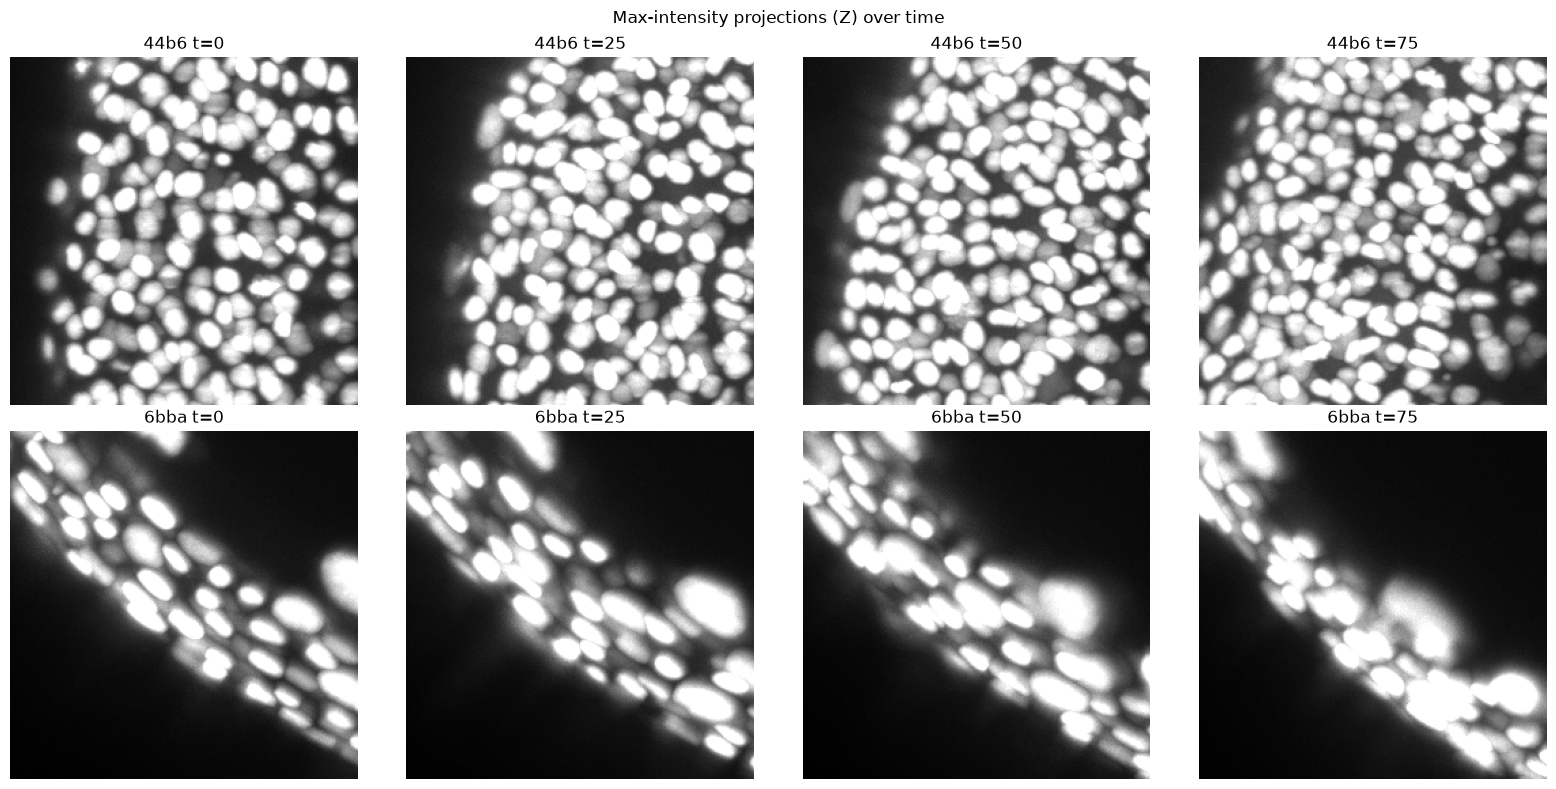

In [6]:
# Max-intensity-projection montage across a few timepoints, contrast-stretched via each
# sample's own 1%/99% intensity quantiles.
timepoints = [0, 25, 50, 75]
fig, axes = plt.subplots(2, len(timepoints), figsize=(4 * len(timepoints), 8))

for row, (prefix, g) in enumerate(image_groups.items()):
    arr = g["0"]
    q = dict(g.attrs)["image_statistics"]["quantiles"]
    vmin, vmax = q["0.01"], q["0.99"]
    for col, t in enumerate(timepoints):
        vol = arr[t, :, :, :]
        mip = vol.max(axis=0)
        ax = axes[row, col]
        ax.imshow(mip, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(f"{prefix} t={t}")
        ax.axis("off")

fig.suptitle("Max-intensity projections (Z) over time")
fig.tight_layout()
plt.show()


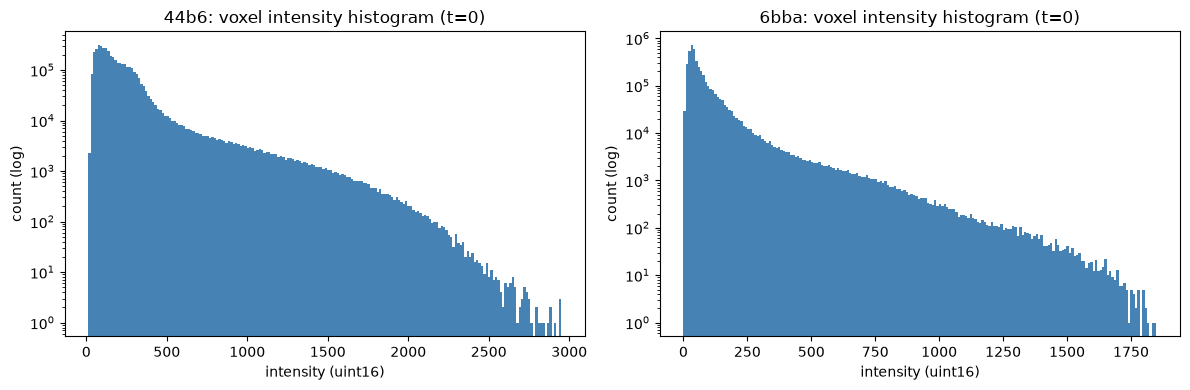

In [7]:
# Intensity histograms (single mid-volume timepoint per sample)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (prefix, g) in zip(axes, image_groups.items()):
    vol = g["0"][0, :, :, :]
    ax.hist(vol.ravel(), bins=200, log=True, color="steelblue")
    ax.set_title(f"{prefix}: voxel intensity histogram (t=0)")
    ax.set_xlabel("intensity (uint16)")
    ax.set_ylabel("count (log)")
fig.tight_layout()
plt.show()


## 3. Ground-truth graph (`.geff`) deep-dive

`.geff` is a zarr v3 group, not a flat file:
- `nodes/ids` — `(N,)` node ids
- `nodes/props/{t,z,y,x}/values` — `(N,)` per-node coordinates
- `edges/ids` — `(E, 2)` `(source, target)` node-id pairs

A division = a node whose id appears more than once as an edge source (out-degree ≥ 2).


In [8]:
def load_geff(sid):
    g = zarr.open_group(store, path=f"train/{sid}.geff", mode="r")
    nodes = pd.DataFrame(
        {
            "node_id": g["nodes/ids"][:],
            "t": g["nodes/props/t/values"][:],
            "z": g["nodes/props/z/values"][:],
            "y": g["nodes/props/y/values"][:],
            "x": g["nodes/props/x/values"][:],
        }
    )
    edges = pd.DataFrame(g["edges/ids"][:], columns=["source", "target"])
    return nodes, edges


geff_data = {}
for prefix, sid in SAMPLE_IDS.items():
    nodes, edges = load_geff(sid)
    geff_data[prefix] = (nodes, edges)
    out_deg = edges["source"].value_counts()
    n_divisions = int((out_deg >= 2).sum())
    print(f"--- {prefix} ({sid}) ---")
    print(f"  nodes: {len(nodes)}  edges: {len(edges)}  divisions (out-degree>=2): {n_divisions}")
    print(f"  t range: {nodes['t'].min()}-{nodes['t'].max()} (volume covers t=0-99)")


--- 44b6 (44b6_0113de3b) ---
  nodes: 52  edges: 50  divisions (out-degree>=2): 0
  t range: 0-75 (volume covers t=0-99)
--- 6bba (6bba_05b6850b) ---
  nodes: 861  edges: 845  divisions (out-degree>=2): 0
  t range: 0-99 (volume covers t=0-99)


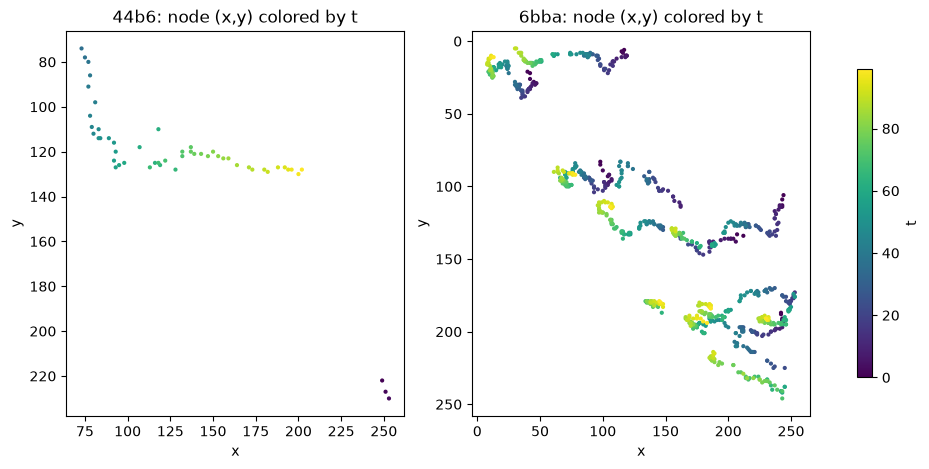

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (prefix, (nodes, edges)) in zip(axes, geff_data.items()):
    sc = ax.scatter(nodes["x"], nodes["y"], c=nodes["t"], cmap="viridis", s=4)
    ax.set_title(f"{prefix}: node (x,y) colored by t")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.invert_yaxis()
fig.colorbar(sc, ax=axes, label="t", shrink=0.8)
plt.show()


In [10]:
# Lineage graph for one division event
prefix = "44b6"
nodes, edges = geff_data[prefix]
out_deg = edges["source"].value_counts()
dividing_nodes = out_deg[out_deg >= 2].index

G = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.DiGraph)
node_t = nodes.set_index("node_id")["t"]

if len(dividing_nodes) > 0:
    root = dividing_nodes[0]
    # descendants + a short window of ancestors for context
    descendants = nx.descendants(G, root) | {root}
    ancestors = set(list(nx.ancestors(G, root))[-5:]) if G.in_degree(root) else set()
    sub_nodes = descendants | ancestors
    sub = G.subgraph(sub_nodes)

    pos = {n: (node_t[n], -n) for n in sub.nodes}
    plt.figure(figsize=(8, 5))
    nx.draw(
        sub, pos, node_size=30, arrows=True, with_labels=False,
        node_color=["red" if n in dividing_nodes else "steelblue" for n in sub.nodes],
    )
    plt.xlabel("t")
    plt.title(f"{prefix}: lineage subtree around division node {root} (red = division)")
    plt.show()
else:
    print("No divisions found in this sample.")


No divisions found in this sample.


## 4. Cross-sample metadata scan (all 199 train samples)

Reads only small per-sample `zarr.json` metadata files (array shapes give node/edge counts for
free; `.geff` group attributes give the t/z/y/x coverage) — no bulk pixel or edge data is loaded
here, so this scan is cheap. Division counts require the actual edge list, so those are read via
`zarr` per sample (slower, still tractable for 199 samples).


In [11]:
def geff_json_summary(base):
    # base like '44b6_0113de3b.geff'
    top = json.loads(zf.read(f"train/{base}/zarr.json"))["attributes"]["geff"]
    n_nodes = json.loads(zf.read(f"train/{base}/nodes/ids/zarr.json"))["shape"][0]
    n_edges = json.loads(zf.read(f"train/{base}/edges/ids/zarr.json"))["shape"][0]
    axes = {a["name"]: (a["min"], a["max"]) for a in top["axes"]}
    return n_nodes, n_edges, axes


rows = []
for zbase in train_zarr:
    sid = zbase[: -len(".zarr")]
    prefix = sid.split("_")[0]
    gbase = f"{sid}.geff"
    n_nodes, n_edges, axes = geff_json_summary(gbase)
    rows.append(
        {
            "sample_id": sid,
            "prefix": prefix,
            "n_nodes": n_nodes,
            "n_edges": n_edges,
            "t_min": axes["t"][0],
            "t_max": axes["t"][1],
        }
    )

summary_df = pd.DataFrame(rows)
summary_df["t_coverage"] = summary_df["t_max"] - summary_df["t_min"] + 1
print(summary_df.shape)
summary_df.head()


(199, 7)


,sample_id,prefix,n_nodes,n_edges,t_min,t_max,t_coverage
0,44b6_0113de3b,44b6,52,50,0.0,75.0,76.0
1,44b6_0b24845f,44b6,51,49,11.0,50.0,40.0
2,44b6_0c582fdc,44b6,71,70,20.0,90.0,71.0
3,44b6_0db75fae,44b6,157,151,0.0,88.0,89.0
4,44b6_12dfb391,44b6,788,773,0.0,99.0,100.0


In [12]:
# Division counts per sample (requires reading each sample's edge list)
division_counts = []
for sid in summary_df["sample_id"]:
    arr = zarr.open_array(store, path=f"train/{sid}.geff/edges/ids", mode="r")
    edges = arr[:]
    if len(edges) == 0:
        division_counts.append(0)
        continue
    _, counts = np.unique(edges[:, 0], return_counts=True)
    division_counts.append(int((counts >= 2).sum()))

summary_df["n_divisions"] = division_counts
summary_df.describe(include="all")


,sample_id,prefix,n_nodes,n_edges,t_min,t_max,t_coverage,n_divisions
count,199,199,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
unique,199,2,NaN,NaN,NaN,NaN,NaN,NaN
top,44b6_0113de3b,6bba,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,128,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,669.939698,647.653266,1.914573,96.572864,95.658291,0.758794
std,NaN,NaN,421.410482,406.297691,6.075929,7.871664,11.091166,1.069367
min,NaN,NaN,50.000000,49.000000,0.000000,50.000000,40.000000,0.000000
25%,NaN,NaN,294.000000,286.000000,0.000000,99.000000,100.000000,0.000000
50%,NaN,NaN,659.000000,639.000000,0.000000,99.000000,100.000000,0.000000
75%,NaN,NaN,939.500000,918.500000,0.000000,99.000000,100.000000,1.000000


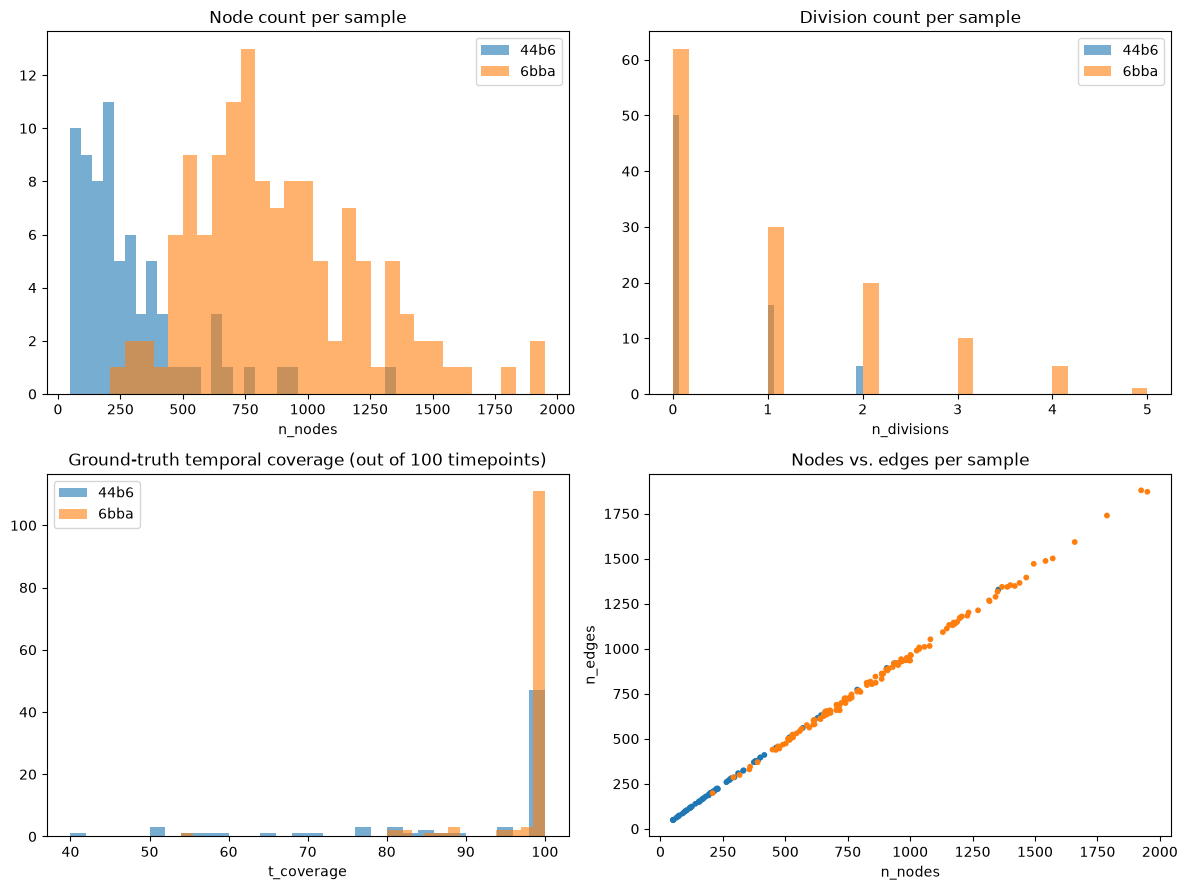

prefix                    44b6         6bba
n_nodes     count    71.000000   128.000000
            mean    284.464789   883.757812
            std     237.107560   341.659953
            min      50.000000   209.000000
            25%     123.500000   654.750000
            50%     214.000000   826.500000
            75%     377.000000  1078.750000
            max    1353.000000  1950.000000
n_edges     count    71.000000   128.000000
            mean    279.239437   852.007812
            std     232.938647   330.890673
            min      49.000000   198.000000
            25%     121.500000   632.000000
            50%     209.000000   800.500000
            75%     370.500000  1024.250000
            max    1328.000000  1879.000000
n_divisions count    71.000000   128.000000
            mean      0.366197     0.976562
            std       0.615036     1.200163
            min       0.000000     0.000000
            25%       0.000000     0.000000
            50%       0.000000     1.000000
            75%       1.000000     2.000000
            max       2.000000     5.000000
t_coverage  count    71.000000   128.000000
            mean     90.802817    98.351562
            std      15.904734     5.645136
            min      40.000000    54.000000
            25%      84.500000   100.000000
            50%     100.000000   100.000000
            75%     100.000000   100.000000
            max     100.000000   100.000000

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for prefix, sub in summary_df.groupby("prefix"):
    axes[0, 0].hist(sub["n_nodes"], bins=30, alpha=0.6, label=prefix)
axes[0, 0].set_title("Node count per sample")
axes[0, 0].set_xlabel("n_nodes")
axes[0, 0].legend()

for prefix, sub in summary_df.groupby("prefix"):
    axes[0, 1].hist(sub["n_divisions"], bins=30, alpha=0.6, label=prefix)
axes[0, 1].set_title("Division count per sample")
axes[0, 1].set_xlabel("n_divisions")
axes[0, 1].legend()

for prefix, sub in summary_df.groupby("prefix"):
    axes[1, 0].hist(sub["t_coverage"], bins=30, alpha=0.6, label=prefix)
axes[1, 0].set_title("Ground-truth temporal coverage (out of 100 timepoints)")
axes[1, 0].set_xlabel("t_coverage")
axes[1, 0].legend()

axes[1, 1].scatter(summary_df["n_nodes"], summary_df["n_edges"], c=summary_df["prefix"].map({"44b6": "C0", "6bba": "C1"}), s=10)
axes[1, 1].set_title("Nodes vs. edges per sample")
axes[1, 1].set_xlabel("n_nodes")
axes[1, 1].set_ylabel("n_edges")

fig.tight_layout()
plt.show()

summary_df.groupby("prefix")[["n_nodes", "n_edges", "n_divisions", "t_coverage"]].describe().T


## 5. Sparse-labeling quantification

In [14]:
full_coverage = (summary_df["t_min"] == 0) & (summary_df["t_max"] == 99)
print(f"Samples with full t=0-99 coverage: {full_coverage.sum()} / {len(summary_df)} ({full_coverage.mean():.1%})")
print(f"Samples with partial t coverage:   {(~full_coverage).sum()} / {len(summary_df)} ({(~full_coverage).mean():.1%})")
print()
print("t_coverage distribution (timepoints labeled out of 100):")
print(summary_df["t_coverage"].describe())
print()
print("Partial-coverage examples:")
summary_df.loc[~full_coverage, ["sample_id", "prefix", "t_min", "t_max", "t_coverage"]].sort_values("t_coverage").head(10)


Samples with full t=0-99 coverage: 156 / 199 (78.4%)
Samples with partial t coverage:   43 / 199 (21.6%)

t_coverage distribution (timepoints labeled out of 100):
count    199.000000
mean      95.658291
std       11.091166
min       40.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: t_coverage, dtype: float64

Partial-coverage examples:


,sample_id,prefix,t_min,t_max,t_coverage
1,44b6_0b24845f,44b6,11.0,50.0,40.0
13,44b6_33b596bf,44b6,21.0,70.0,50.0
19,44b6_53f95252,44b6,0.0,50.0,51.0
65,44b6_e29f0176,44b6,30.0,80.0,51.0
131,6bba_767a1e17,6bba,46.0,99.0,54.0
49,44b6_c15fded2,44b6,21.0,74.0,54.0
37,44b6_90724892,44b6,29.0,85.0,57.0
47,44b6_abf82518,44b6,0.0,57.0,58.0
70,44b6_f28707c6,44b6,8.0,72.0,65.0
59,44b6_d754aa59,44b6,8.0,75.0,68.0


## 6. Test set inspection

In [15]:
test_rows = []
for zbase in test_bases:
    sid = zbase[: -len(".zarr")] if zbase.endswith(".zarr") else zbase
    g = zarr.open_group(store, path=f"test/{zbase}", mode="r")
    arr = g["0"]
    attrs = dict(g.attrs)
    q = attrs["image_statistics"]["quantiles"]
    test_rows.append(
        {
            "sample_id": sid,
            "prefix": sid.split("_")[0],
            "shape": arr.shape,
            "dtype": str(arr.dtype),
            "q01": q["0.01"],
            "q99": q["0.99"],
        }
    )

test_df = pd.DataFrame(test_rows)
print("Test dataset ids match sample_submission.csv:", set(test_df["sample_id"]) == set(sub_df["dataset"].unique()))
test_df


Test dataset ids match sample_submission.csv: True


,sample_id,prefix,shape,dtype,q01,q99
0,44b6_0113de3b,44b6,"(100, 64, 256, 256)",uint16,38.0,1478.000000
1,44b6_0b24845f,44b6,"(100, 64, 256, 256)",uint16,84.0,2902.377778
2,6bba_05b6850b,6bba,"(100, 64, 256, 256)",uint16,12.0,769.000000
3,6bba_05db0fb1,6bba,"(100, 64, 256, 256)",uint16,158.0,2307.000000


## 7. Chunking / storage notes

- Each image array is chunked as one full Z-stack per timepoint: `chunk_shape = (1, 64, 256, 256)`,
  compressed with `blosc` (`zstd`, bitshuffle). A single chunk of raw `uint16` data
  (`64*256*256*2` bytes ≈ 8.4 MB) compresses to roughly half that.
- `.geff` arrays use plain `zstd` (no bitshuffle) since they're small 1-D/2-D integer arrays, not
  image blocks.
- Because the zarr chunks are already compressed on disk, the outer zip adds negligible further
  compression — the 87GB archive size is essentially the sum of the already-compressed zarr chunks.


In [16]:
chunk_info = zf.getinfo("train/44b6_0113de3b.zarr/0/c/0/0/0/0")
raw_uncompressed = 64 * 256 * 256 * 2
print(f"Raw uncompressed chunk size: {raw_uncompressed:,} bytes")
print(f"Blosc-compressed size stored in zip (zip 'file_size'): {chunk_info.file_size:,} bytes")
print(f"Zip's own further compression ('compress_size'):        {chunk_info.compress_size:,} bytes")
print(f"Zip compress_type code: {chunk_info.compress_type} (8 = deflate; near-zero gain over blosc)")


Raw uncompressed chunk size: 8,388,608 bytes
Blosc-compressed size stored in zip (zip 'file_size'): 4,469,062 bytes
Zip's own further compression ('compress_size'):        4,458,506 bytes
Zip compress_type code: 8 (8 = deflate; near-zero gain over blosc)


## 8. Summary of findings

- **Two distinct dataset regimes** by filename prefix: `44b6` (71 train samples, dense — tens of
  thousands of nodes/sample) vs. `6bba` (128 train samples, sparser — thousands of nodes/sample).
  Any model/eval split should stratify by this prefix, and per-source normalization or handling
  may be needed given the density gap.
- **Fixed volume geometry**: every sample (train and test) is `(T=100, Z=64, Y=256, X=256)`
  `uint16`, physical scale `z=1.625 µm`, `y=x=0.40625 µm/voxel` — matches the evaluation metric's
  scale constants exactly.
- **Ground truth is genuinely sparse in time**: a meaningful fraction of train samples only label
  a sub-range of the 100 timepoints (see section 5), consistent with the metric's note that GT is
  sparsely labeled — models/eval code must handle partial temporal coverage per sample, not assume
  every timepoint has annotations.
- **Divisions are rare relative to node count** but present in both dataset sources — worth a
  dedicated division-detection component given the metric's explicit `division_jaccard` term.
- **Data format**: both images and `.geff` ground truth are zarr v3 groups embedded in one zip.
  For the actual pipeline it's more practical to read directly via `zarr.storage.ZipStore`
  (as done throughout this notebook) than to extract 87GB to disk.
